# Prostate Cancer Data: EDA v4

Rerunnable EDA. Run top to bottom; Section 12 prints a summary of every check.

**Changes vs v3**
* Ink regions: small regions near the tissue edge are dropped; the result is checked against the number of MRI cancer lesions.

**Changes vs v2**
* Prostate mask is no longer used to filter voxels (it is incomplete); Section 4b diagnoses why.
* PIA and the classic fit (`orig_output`) are compared as two estimators; the r² filter is dropped.
* New feature sets (compact v_ep, v_lu, ADC; classic fit) and a fair comparison with the lab map.
* Unusable slides are detected and skipped.
* Ink pipeline v1: tuned parameters, flags for ambiguous regions, a tile table with ink exclusion, and GeoJSON regions for QuPath.
* All key figures are saved to `OUT_DIR/figures`.

**Terms used in code**
* *76 grid*: the cropped 76×76×Z grid where all PIA maps live.
* *labeled voxels*: voxels inside a cancer or benign mask. Everything else is unlabeled, not benign.
* *classic fit*: `orig_output`, prefixed `o_` in code. *PIA*: the lab's trained model, `pia`.

## 0. Install and mount

In [3]:
!pip install -q "imagecodecs[all]" tifffile scikit-image

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.1/28.1 MB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 69.3 MB/s eta 0:00:00


In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab; skipping Drive mount.')

Mounted at /content/drive


## 1. Setup

In [4]:
import os, re, json, warnings, logging
import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
import tifffile
import imagecodecs
from PIL import Image
from scipy import ndimage as ndi
from skimage.color import rgb2hsv
from skimage.morphology import convex_hull_image
from skimage import measure
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from IPython.display import display

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
warnings.filterwarnings('ignore', category=RuntimeWarning)
logging.getLogger('tifffile').setLevel(logging.ERROR)   # quiet repeated warnings on damaged files

DATA_DIR = '/content/drive/MyDrive/spring/capstone/data'
assert os.path.isdir(DATA_DIR) and any(f.endswith('.mat') for f in os.listdir(DATA_DIR)), \
    f'No .mat files at {DATA_DIR}. Is Drive mounted, and is the path right?'
OUT_DIR  = os.path.join(DATA_DIR, 'eda_v4_outputs')
FIG_DIR  = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

PATIENTS  = ['pt104', 'pt107', 'pt109', 'pt111', 'pt112']
MAT_FILES = {pt: os.path.join(DATA_DIR, f'irb13_pat{pt[2:]}_cons_pts.mat') for pt in PATIENTS}
TIF_FILES = {pt: os.path.join(DATA_DIR, f'{pt}.ome.tif') for pt in PATIENTS}

PIA_PARAMS = ['adc_map', 'v_ep', 'v_st', 'v_lu', 'd_ep', 'd_st', 'd_lu', 't2_ep', 't2_st', 't2_lu']
R2_THRESH  = 0.8   # used only to document fit quality (Section 6), not to filter

REPORT = {}        # each check stores its key result here; printed in Section 12

def as_list(x):
    if x is None: return []
    return x if isinstance(x, list) else [x]

def disk(r):
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    return x * x + y * y <= r * r

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=150, bbox_inches='tight')

# Fast morphology via distance transforms (exact disk shapes, fine for large radii)
def dilate(mask, r):
    return ndi.distance_transform_edt(~mask) <= r if (r > 0 and mask.any()) else mask.copy()

def erode(mask, r):
    return ndi.distance_transform_edt(mask) > r if (r > 0 and mask.any()) else mask.copy()

def close(mask, r):
    return erode(dilate(mask, r), r)

def drop_small(mask, min_px):
    lab, n = ndi.label(mask)
    if n == 0: return mask
    sizes = np.bincount(lab.ravel())
    keep = sizes >= min_px
    keep[0] = False
    return keep[lab]

print('Setup done.')

Setup done.


## 1b. Data folder inventory
Looks for annotation files (QuPath, ImageScope, spreadsheets) that may hold Gleason grades or region outlines.

In [5]:
rows = []
for root, _, files in os.walk(DATA_DIR):
    if os.path.relpath(root, DATA_DIR).split(os.sep)[0].startswith('eda_'):   # skip this notebook's own output folders
        continue
    for f in files:
        p = os.path.join(root, f)
        low = f.lower()
        ext = '.ome.tif' if low.endswith('.ome.tif') else os.path.splitext(low)[1]
        rows.append({'file': os.path.relpath(p, DATA_DIR), 'ext': ext,
                     'size_MB': round(os.path.getsize(p) / 1e6, 2)})
inv = pd.DataFrame(rows).sort_values('file')
display(inv)

ANNOT_EXT = {'.xml', '.geojson', '.json', '.csv', '.qpproj', '.qpdata', '.txt', '.xlsx', '.xls', '.tsv'}
annot = inv[inv['ext'].isin(ANNOT_EXT)]
print('Candidate annotation files:', annot['file'].tolist() if len(annot) else 'none')

REPORT['1_file_types'] = inv['ext'].value_counts().to_dict()
REPORT['1_annotation_candidates'] = annot['file'].tolist()
REPORT['1_missing_mat'] = [pt for pt, p in MAT_FILES.items() if not os.path.exists(p)]
REPORT['1_missing_tif'] = [pt for pt, p in TIF_FILES.items() if not os.path.exists(p)]

,file,ext,size_MB
0,irb13_pat104_cons_pts.mat,.mat,130.21
1,irb13_pat107_cons_pts.mat,.mat,145.91
2,irb13_pat109_cons_pts.mat,.mat,126.36
3,irb13_pat111_cons_pts.mat,.mat,140.33
4,irb13_pat112_cons_pts.mat,.mat,124.24
5,pt104.ome.tif,.ome.tif,1218.30
8,pt107.ome.tif,.ome.tif,625.55
6,pt109.ome.tif,.ome.tif,891.06
7,pt112.ome.tif,.ome.tif,1101.00


Candidate annotation files: none


## 2. MAT files: documentation and lesion structure

In [6]:
mats = {pt: scipy.io.loadmat(p, simplify_cells=True) for pt, p in MAT_FILES.items() if os.path.exists(p)}
print('Loaded:', list(mats))
REPORT['2_mat_loaded'] = list(mats)

Loaded: ['pt104', 'pt107', 'pt109', 'pt111', 'pt112']


### 2a. readme_doc
v1 skipped these. They are the lab's own documentation of every field. Read them fully.

In [7]:
def print_readmes(mat):
    if 'readme_doc' in mat:
        print('=== top level ===\n' + str(mat['readme_doc']))
    for k, v in mat.items():
        if isinstance(v, dict) and 'readme_doc' in v:
            print(f'\n=== {k} ===\n' + str(v['readme_doc']))

first_pt = next(iter(mats))
print_readmes(mats[first_pt])

# Are the readmes identical across patients?
same = all(str(m.get('readme_doc')) == str(mats[first_pt].get('readme_doc')) for m in mats.values())
REPORT['2a_readme_identical_across_patients'] = same

=== top level ===

Consolidated MAT file
---------------------

This file contains the assimilated input used and output generated
from the "original run" or "standard run" (like from a clinical trial)
of hybrid (usually OneShotHybrid), along with extra data.

It consists of a set of at least 5 top-level variables, which can be read in
as a structure (or similar).  The variables themselves are generally
structures.  Other data, such as alternative output, or truth, can be
added as peers of these top-level variables, but the contents of the
5 initial top-level variables themselves should not be changed.  These
initial variables are:

orig_input: This contains the de-identified, sorted, and transformed
   data from the hybrid series that were read in for the run.

orig_output: Hybrid-generated output parameters from the original run,
   including diffusivities, compartment volumes, final predicted map,
   and much other data.

additional_info: Additional information generated for the cas

### 2b. What is inside each cancer / benign item
`cancers` and `benigns` are lists; each item is a dict (a MATLAB struct). v1 printed the values but not the keys.

In [8]:
def describe(v):
    if isinstance(v, np.ndarray):
        s = f'array {v.shape} {v.dtype}'
        if v.dtype.kind in 'iub' and v.size: s += f' sum={int(v.sum())}'
        return s
    return f'{type(v).__name__}: {repr(v)[:80]}'

mat0 = mats[first_pt]
for kind in ['cancers', 'benigns']:
    items = as_list(mat0.get(kind))
    print(f'\n{first_pt}.{kind}: {type(mat0.get(kind)).__name__} with {len(items)} item(s)')
    for i, it in enumerate(items):
        print(f'  item[{i}]  ({type(it).__name__})')
        if isinstance(it, dict):
            for k, v in it.items():
                print(f'      {k:<28} {describe(v)}')

# Non-array fields of every item, all patients
recs, keysets = [], {'cancers': set(), 'benigns': set()}
for pt, mat in mats.items():
    for kind in ['cancers', 'benigns']:
        for i, it in enumerate(as_list(mat.get(kind))):
            if not isinstance(it, dict): continue
            keysets[kind] |= set(it.keys())
            r = {'patient': pt, 'kind': kind, 'idx': i}
            r.update({k: v for k, v in it.items() if not isinstance(v, np.ndarray)})
            recs.append(r)
lesion_fields = pd.DataFrame(recs)
display(lesion_fields)

REPORT['2b_cancer_keys'] = sorted(keysets['cancers'])
REPORT['2b_benign_keys'] = sorted(keysets['benigns'])
REPORT['2b_counts'] = lesion_fields.groupby(['patient', 'kind']).size().unstack(fill_value=0).to_dict()
# Unique values of each text field, to find what 'unset' belongs to
REPORT['2b_text_field_values'] = {c: sorted(map(str, lesion_fields[c].dropna().unique()))[:15]
                                  for c in lesion_fields.columns
                                  if c not in ('patient', 'kind', 'idx') and lesion_fields[c].map(lambda v: isinstance(v, str)).any()}


pt104.cancers: dict with 1 item(s)
  item[0]  (dict)
      cancer_number                int: 1
      name                         str: 'Cancer 1 1203'
      gleason_score                str: 'unset'
      drawn_on_series              str: 'hybrid_adc'
      mask_hybrid_adc              array (128, 128, 18) uint8 sum=1526
      mask_hybrid_low_te           array (128, 128, 18) uint8 sum=1526
      mask_t2                      array (512, 512, 24) uint8 sum=34095
      mask_unk1303                 array (128, 128, 18) uint8 sum=1526
      mask_hybrid_cropped          array (76, 76, 18) uint8 sum=1526

pt104.benigns: list with 3 item(s)
  item[0]  (dict)
      benign_set_name              str: 'Normal 1303'
      drawn_on_series              str: 'unk1303'
      mask_hybrid_adc              array (128, 128, 18) uint8 sum=60
      mask_hybrid_low_te           array (128, 128, 18) uint8 sum=60
      mask_t2                      array (512, 512, 24) uint8 sum=1192
      mask_unk1303        

,patient,kind,idx,cancer_number,name,gleason_score,drawn_on_series,benign_set_name
0,pt104,cancers,0,1.0,Cancer 1 1203,unset,hybrid_adc,NaN
1,pt104,benigns,0,NaN,NaN,NaN,unk1303,Normal 1303
2,pt104,benigns,1,NaN,NaN,NaN,unk1303,Normal 1303
3,pt104,benigns,2,NaN,NaN,NaN,unk1303,Normal 1303
4,pt107,cancers,0,1.0,Ulas cancer 1 1503 right,unset,hybrid_adc,NaN
5,pt107,cancers,1,2.0,Ulas cancer 2 1503 left,unset,hybrid_adc,NaN
6,pt107,benigns,0,NaN,NaN,NaN,hybrid_adc,Ulas normal 1503 right
7,pt107,benigns,1,NaN,NaN,NaN,hybrid_adc,Ulas normal 1503 right
8,pt107,benigns,2,NaN,NaN,NaN,hybrid_adc,Ulas normal 1503 right
9,pt109,cancers,0,1.0,Ulas cancer 1 left 803,unset,hybrid_adc,NaN


## 3. Grid alignment: crop vs resize
The PIA maps are a 76×76 crop of the 128×128 grid. This finds the crop offset directly from the prostate masks,
checks every lesion mask against it, and measures how wrong the v1 resize was.

In [9]:
def find_mask(item, space, shape=None):
    key = f'mask_{space}'
    if key in item: return np.asarray(item[key])
    for k, v in item.items():
        if isinstance(v, np.ndarray) and v.ndim == 3 and space in k:
            return np.asarray(v)
    if shape is not None:
        for k, v in item.items():
            if isinstance(v, np.ndarray) and v.shape == shape:
                return np.asarray(v)
    return None

def best_offset(big, small):
    n0, n1 = small.shape[:2]
    best = None
    for r0 in range(big.shape[0] - n0 + 1):
        for c0 in range(big.shape[1] - n1 + 1):
            mism = int(np.count_nonzero(big[r0:r0 + n0, c0:c0 + n1] != small))
            if best is None or mism < best[2]:
                best = (r0, c0, mism)
    return best

def resize_nearest_v1(mask, shape):
    # the v1 method, kept only to measure its error
    out = np.zeros(shape, np.uint8)
    for z in range(min(mask.shape[2], shape[2])):
        im = Image.fromarray(mask[:, :, z].astype(np.uint8))
        out[:, :, z] = np.array(im.resize((shape[1], shape[0]), Image.NEAREST))
    return out.astype(bool)

align, rows = {}, []
for pt, mat in mats.items():
    shape76 = mat['pia']['v_ep'].shape
    rect = np.asarray(mat['orig_input']['crop_rectangle']).ravel().tolist()
    p128 = mat['prostate']['hybrid_adc'].astype(bool)
    p76 = mat['prostate']['hybrid_cropped'].astype(bool)
    r0, c0, mism = best_offset(p128, p76)
    align[pt] = (r0, c0)
    for kind in ['cancers', 'benigns']:
        for i, it in enumerate(as_list(mat.get(kind))):
            m128 = find_mask(it, 'hybrid_adc').astype(bool)
            m76 = find_mask(it, 'hybrid_cropped', shape76).astype(bool)
            crop = m128[r0:r0 + shape76[0], c0:c0 + shape76[1]]
            v1 = resize_nearest_v1(m128, shape76)
            rows.append({'patient': pt, 'kind': kind, 'idx': i,
                         'crop_rect': rect, 'offset(r,c)': (r0, c0),
                         'prostate_mismatch': mism,
                         'n_true_76': int(m76.sum()), 'n_128': int(m128.sum()),
                         'crop_mismatch': int(np.count_nonzero(crop != m76)),
                         'n_v1_resized': int(v1.sum()),
                         'v1_frac_truly_in_mask': round(float((v1 & m76).sum() / max(v1.sum(), 1)), 3)})
align_df = pd.DataFrame(rows)
display(align_df)

REPORT['3_offsets'] = {pt: list(map(int, v)) for pt, v in align.items()}
REPORT['3_crop_rects'] = align_df.groupby('patient')['crop_rect'].first().astype(str).to_dict()
REPORT['3_total_crop_mismatch_voxels'] = int(align_df['crop_mismatch'].sum())
REPORT['3_prostate_mismatch'] = align_df.groupby('patient')['prostate_mismatch'].first().to_dict()
REPORT['3_v1_resize_mean_frac_correct'] = round(float(align_df['v1_frac_truly_in_mask'].mean()), 3)

,patient,kind,idx,crop_rect,"offset(r,c)",prostate_mismatch,n_true_76,n_128,crop_mismatch,n_v1_resized,v1_frac_truly_in_mask
0,pt104,cancers,0,"[25, 25, 100, 100]","(24, 24)",0,1526,1526,0,529,0.522
1,pt104,benigns,0,"[25, 25, 100, 100]","(24, 24)",0,60,60,0,20,0.000
2,pt104,benigns,1,"[25, 25, 100, 100]","(24, 24)",0,55,55,0,19,0.000
3,pt104,benigns,2,"[25, 25, 100, 100]","(24, 24)",0,64,64,0,21,0.048
4,pt107,cancers,0,"[25, 25, 100, 100]","(24, 24)",0,317,317,0,117,0.974
5,pt107,cancers,1,"[25, 25, 100, 100]","(24, 24)",0,718,718,0,256,0.562
6,pt107,benigns,0,"[25, 25, 100, 100]","(24, 24)",0,194,194,0,66,0.924
7,pt107,benigns,1,"[25, 25, 100, 100]","(24, 24)",0,96,96,0,32,0.875
8,pt107,benigns,2,"[25, 25, 100, 100]","(24, 24)",0,136,136,0,44,0.955
9,pt109,cancers,0,"[25, 25, 100, 100]","(24, 24)",0,512,512,0,187,0.048


## 4. Build one dataset per patient on the 76 grid
Everything below uses this. Masks come from the file's own 76×76 masks.

In [10]:
def union(masks, shape):
    out = np.zeros(shape, bool)
    for m in masks: out |= m
    return out

data = {}
for pt, mat in mats.items():
    pia, oo, oi = mat['pia'], mat['orig_output'], mat['orig_input']
    shape76 = pia['v_ep'].shape
    r0, c0 = align[pt]
    d = {'shape': shape76}
    for p in PIA_PARAMS:
        d[p] = np.asarray(pia[p], float)
    d['orig'] = {k: np.asarray(v, float) for k, v in oo.items()
                 if isinstance(v, np.ndarray) and v.shape == shape76}
    for p in PIA_PARAMS:
        d['o_' + p] = d['orig']['adc' if p == 'adc_map' else p]   # classic fit, same names with o_ prefix
    d['r2'] = d['orig']['r_square']
    d['adc_r2'] = d['orig'].get('adc_r_square')
    d['prostate'] = np.asarray(mat['prostate']['hybrid_cropped']).astype(bool)
    d['cancer_lesions'] = [find_mask(it, 'hybrid_cropped', shape76).astype(bool) for it in as_list(mat.get('cancers'))]
    d['benign_rois'] = [find_mask(it, 'hybrid_cropped', shape76).astype(bool) for it in as_list(mat.get('benigns'))]
    d['cancer'] = union(d['cancer_lesions'], shape76)
    d['benign'] = union(d['benign_rois'], shape76)
    scan = np.asarray(mat['series']['hybrid_adc']['image_volume'], float)
    d['scan_adc'] = scan[r0:r0 + shape76[0], c0:c0 + shape76[1]]
    raw = np.asarray(oi['hybrid_data_cropped'], float)
    d['raw16'] = raw.reshape(*shape76, -1)
    preds = {'pred_cancer_mask': oo.get('pred_cancer_mask'),
             'pred_cancer_mask_wo': (mat.get('additional_info') or {}).get('pred_cancer_mask_wo'),
             'pia_trad_pred_map': pia.get('pia_trad_pred_map'),
             'pia_trad_pred_map_wo': pia.get('pia_trad_pred_map_wo')}
    d['lab_preds'] = {k: np.asarray(v).astype(bool) for k, v in preds.items() if v is not None}
    data[pt] = d

rows = []
for pt, d in data.items():
    rows.append({'patient': pt, 'shape76': d['shape'],
                 'prostate_vox': int(d['prostate'].sum()),
                 'cancer_vox': int(d['cancer'].sum()), 'benign_vox': int(d['benign'].sum()),
                 'n_cancer_lesions': len(d['cancer_lesions']), 'n_benign_rois': len(d['benign_rois']),
                 'cancer_benign_overlap': int((d['cancer'] & d['benign']).sum()),
                 'cancer_frac_in_prostate': round(float((d['cancer'] & d['prostate']).sum() / max(d['cancer'].sum(), 1)), 3),
                 'benign_frac_in_prostate': round(float((d['benign'] & d['prostate']).sum() / max(d['benign'].sum(), 1)), 3)})
summary_df = pd.DataFrame(rows)
display(summary_df)

oi0 = mats[first_pt]['orig_input']
print('b-values:', np.asarray(oi0['b']).tolist(), '  echo times:', np.asarray(oi0['te']).tolist())
print('hybrid_data_cropped shape:', np.asarray(oi0['hybrid_data_cropped']).shape)
REPORT['4_patient_summary'] = summary_df.set_index('patient').drop(columns='shape76').to_dict('index')

,patient,shape76,prostate_vox,cancer_vox,benign_vox,n_cancer_lesions,n_benign_rois,cancer_benign_overlap,cancer_frac_in_prostate,benign_frac_in_prostate
0,pt104,"(76, 76, 18)",5285,1526,179,1,3,0,0.257,0.966
1,pt107,"(76, 76, 23)",15169,1035,426,2,3,0,0.756,0.993
2,pt109,"(76, 76, 18)",6613,512,183,1,3,0,1.000,1.000
3,pt111,"(76, 76, 18)",2632,706,160,3,3,14,0.504,0.887
4,pt112,"(76, 76, 20)",8928,67,81,1,2,0,0.776,0.691


b-values: [0.0, 150.0, 1000.0, 1500.0]   echo times: [57.0, 70.0, 150.0, 200.0]
hybrid_data_cropped shape: (76, 76, 18, 4, 4)


## 4b. Why is the prostate mask incomplete?
v2 showed cancer voxels outside the prostate mask (only 26% inside for pt104).
Hypothesis: the prostate was outlined on T2 and transferred to the hybrid grid, and hybrid slices with no matching T2 slice come out empty.
For each slice: prostate, cancer and benign voxel counts, the T2 source slice (−1 = none), and whether that T2 slice has a prostate outline.

In [11]:
rows = []
for pt, mat in mats.items():
    d = data[pt]
    Z = d['shape'][2]
    try:
        src = np.asarray(mat['transformers']['t2']['hybrid_cropped']['src_slice_nums']).ravel().astype(int)
    except Exception:
        src = np.full(Z, -999)
    try:
        p_t2 = np.asarray(mat['prostate']['t2']).astype(bool).sum(axis=(0, 1))
    except Exception:
        p_t2 = None
    for z in range(Z):
        s = int(src[z]) if z < len(src) else -999
        t2_has = None
        if p_t2 is not None and 1 <= s <= len(p_t2):
            t2_has = bool(p_t2[s - 1] > 0)          # MATLAB slice numbers start at 1
        rows.append({'patient': pt, 'slice': z,
                     'prostate_vox': int(d['prostate'][:, :, z].sum()),
                     'cancer_vox': int(d['cancer'][:, :, z].sum()),
                     'benign_vox': int(d['benign'][:, :, z].sum()),
                     't2_src_slice': s, 't2_slice_has_prostate': t2_has})
slice_df = pd.DataFrame(rows)

problem = slice_df[(slice_df.cancer_vox + slice_df.benign_vox > 0) & (slice_df.prostate_vox == 0)]
print('Slices with annotations but no prostate mask:')
display(problem)

summ = {}
for pt, g in slice_df.groupby('patient'):
    lab = g[g.cancer_vox + g.benign_vox > 0]
    bad = lab[lab.prostate_vox == 0]
    summ[pt] = {'annotated_slices': len(lab), 'annotated_slices_without_prostate': len(bad),
                'of_those_no_t2_match': int((bad.t2_src_slice < 1).sum()),
                'of_those_t2_slice_not_outlined': int((bad.t2_slice_has_prostate == False).sum())}
display(pd.DataFrame(summ).T)
REPORT['4b_prostate_mask_slices'] = summ

Slices with annotations but no prostate mask:


,patient,slice,prostate_vox,cancer_vox,benign_vox,t2_src_slice,t2_slice_has_prostate
0,pt104,0,0,178,0,3,False
1,pt104,1,0,382,0,4,False
62,pt111,3,0,104,0,8,False


,annotated_slices,annotated_slices_without_prostate,of_those_no_t2_match,of_those_t2_slice_not_outlined
pt104,10,2,0,2
pt107,11,0,0,0
pt109,8,0,0,0
pt111,6,1,0,1
pt112,3,0,0,0


## 5. `pia` vs `orig_output`: two different estimators
The readme says PIA runs a trained model (`pia_model.pt`); `orig_output` is the classic curve fit.
Agreement per parameter, measured on labeled voxels (the prostate mask is incomplete, see 4b).

In [12]:
rows = []
for pt, d in data.items():
    m = d['cancer'] | d['benign']
    for p in PIA_PARAMS:
        a, b = d[p][m], d['o_' + p][m]
        ok = np.isfinite(a) & np.isfinite(b)
        rows.append({'patient': pt, 'param': p,
                     'corr': round(float(np.corrcoef(a[ok], b[ok])[0, 1]), 3) if ok.sum() > 2 and a[ok].std() > 0 and b[ok].std() > 0 else np.nan,
                     'mean_pia': round(float(a[ok].mean()), 3), 'mean_classic': round(float(b[ok].mean()), 3)})
cmp_df = pd.DataFrame(rows)
cmp_pivot = cmp_df.pivot(index='param', columns='patient', values='corr').loc[PIA_PARAMS]
cmp_pivot['mean'] = cmp_pivot.mean(axis=1).round(3)
display(cmp_pivot)
REPORT['5_pia_vs_classic_mean_corr'] = cmp_pivot['mean'].to_dict()

patient,pt104,pt107,pt109,pt111,pt112,mean
param,,,,,,
adc_map,0.753,0.962,0.824,0.574,0.934,0.809
v_ep,0.816,0.922,0.803,0.713,0.727,0.796
v_st,0.877,0.692,0.770,0.730,0.632,0.740
v_lu,0.927,0.974,0.939,0.910,0.934,0.937
d_ep,0.180,0.601,0.020,0.091,0.312,0.241
d_st,0.517,0.731,0.537,0.530,0.618,0.587
d_lu,-0.110,0.353,0.334,0.243,0.488,0.262
t2_ep,0.638,0.572,0.261,0.470,0.483,0.485
t2_st,0.523,0.521,0.422,0.554,0.637,0.531


## 6. Fit quality (documentation)
r² belongs to the classic fit, not to PIA, so it is not used to filter PIA values. v2 showed filtering changed no result.
Kept here to document how many voxels fit poorly. Prostate rows removed because the mask is incomplete.

In [13]:
rows = []
for pt, d in data.items():
    for name, m in {'whole_crop': np.ones(d['shape'], bool), 'cancer': d['cancer'], 'benign': d['benign']}.items():
        r2 = d['r2'][m]
        rows.append({'patient': pt, 'region': name, 'n': int(m.sum()),
                     'median_r2': round(float(np.median(r2)), 3),
                     f'frac_r2<{R2_THRESH}': round(float((r2 < R2_THRESH).mean()), 3),
                     'frac_neg_vlu_classic': round(float((d['orig']['v_lu'][m] < 0).mean()), 3)})
fit_df = pd.DataFrame(rows)
display(fit_df.pivot(index='patient', columns='region', values=f'frac_r2<{R2_THRESH}'))
pool = {}
for name in ['cancer', 'benign']:
    v = np.concatenate([d['r2'][d[name]] for d in data.values()])
    pool[name] = round(float((v < R2_THRESH).mean()), 3)
REPORT['6_pooled_frac_poor_fit'] = pool

region,benign,cancer,whole_crop
patient,,,
pt104,0.011,0.001,0.612
pt107,0.000,0.003,0.630
pt109,0.000,0.002,0.717
pt111,0.006,0.079,0.662
pt112,0.012,0.045,0.617


## 7. Parameters stuck at fitting bounds (labeled voxels)

In [14]:
rows = []
for est, prefix in [('pia', ''), ('classic', 'o_')]:
    for p in ['d_ep', 'd_st', 'd_lu', 't2_ep', 't2_st', 't2_lu', 'v_ep', 'v_st', 'v_lu']:
        v = np.concatenate([d[prefix + p][d['cancer'] | d['benign']] for d in data.values()])
        v = v[np.isfinite(v)]
        lo, hi = v.min(), v.max()
        tol = 1e-3 * (hi - lo) if hi > lo else 1e-9
        rows.append({'estimator': est, 'param': p, 'min': round(float(lo), 4), 'max': round(float(hi), 4),
                     'frac_at_min': round(float((v <= lo + tol).mean()), 3),
                     'frac_at_max': round(float((v >= hi - tol).mean()), 3)})
bounds_df = pd.DataFrame(rows)
display(bounds_df)
REPORT['7_frac_at_bounds'] = {f'{r.estimator}.{r.param}': (r.frac_at_min, r.frac_at_max) for r in bounds_df.itertuples()}

,estimator,param,min,max,frac_at_min,frac_at_max
0,pia,d_ep,0.3000,0.6996,0.001,0.001
1,pia,d_st,0.7029,1.7000,0.000,0.000
2,pia,d_lu,2.7311,2.9933,0.000,0.000
3,pia,t2_ep,20.0000,69.9662,0.010,0.000
4,pia,t2_st,40.0000,99.8908,0.001,0.001
5,pia,t2_lu,500.1567,999.1115,0.000,0.000
6,pia,v_ep,0.0000,0.8353,0.000,0.000
7,pia,v_st,0.0001,0.9999,0.000,0.000
8,pia,v_lu,0.0001,0.8569,0.000,0.000
9,classic,d_ep,0.3000,0.7000,0.378,0.419


## 8. Corrected visualizations
All panels on the 76 grid. Contours: prostate yellow (incomplete on some slices, see 4b), benign green, cancer red.
Figures are saved to `OUT_DIR/figures` for the report.

In [15]:
def show_patient(pt, n_slices=4):
    d = data[pt]
    per_slice = d['cancer'].sum(axis=(0, 1))
    slices = sorted(s for s in np.argsort(per_slice)[::-1][:n_slices] if per_slice[s] > 0)
    body = d['cancer'] | d['benign'] | d['prostate']
    sa = d['scan_adc'][body] if body.any() else d['scan_adc'].ravel()
    panels = [('Scanner ADC series', d['scan_adc'], 'gray', (np.percentile(sa, 1), np.percentile(sa, 99))),
              ('Fitted ADC (adc_map)', d['adc_map'], 'gray', (0, 3)),
              ('Epithelium v_ep', d['v_ep'], 'viridis', (0, 1)),
              ('Lumen v_lu', d['v_lu'], 'viridis', (0, 1)),
              ('Classic fit r²', np.clip(d['r2'], -1, 1), 'RdYlGn', (-1, 1)),
              ('Lab pred_cancer_mask', d['lab_preds'].get('pred_cancer_mask'), 'gray', (0, 1))]
    fig, axes = plt.subplots(len(slices), len(panels), figsize=(2.8 * len(panels), 2.9 * len(slices)), squeeze=False)
    for r, s in enumerate(slices):
        for c, (title, vol, cmap, (lo, hi)) in enumerate(panels):
            ax = axes[r, c]
            ax.axis('off')
            if vol is None: continue
            ax.imshow(vol[:, :, s], cmap=cmap, vmin=lo, vmax=hi)
            for m, col in [(d['prostate'], 'yellow'), (d['benign'], 'lime'), (d['cancer'], 'red')]:
                if m[:, :, s].any():
                    ax.contour(m[:, :, s].astype(float), levels=[0.5], colors=col, linewidths=1)
            ax.set_title(f'{title}\nslice {s}', fontsize=8)
    fig.suptitle(f'{pt}: MRI maps with annotations (76 grid)', fontweight='bold')
    plt.tight_layout(); save_fig(f'mri_{pt}'); plt.show()

for pt in data:
    show_patient(pt)

Output hidden; open in https://colab.research.google.com to view.

### 8b. Distributions, cancer vs benign (all patients pooled)
Top row: PIA. Bottom row: classic fit.

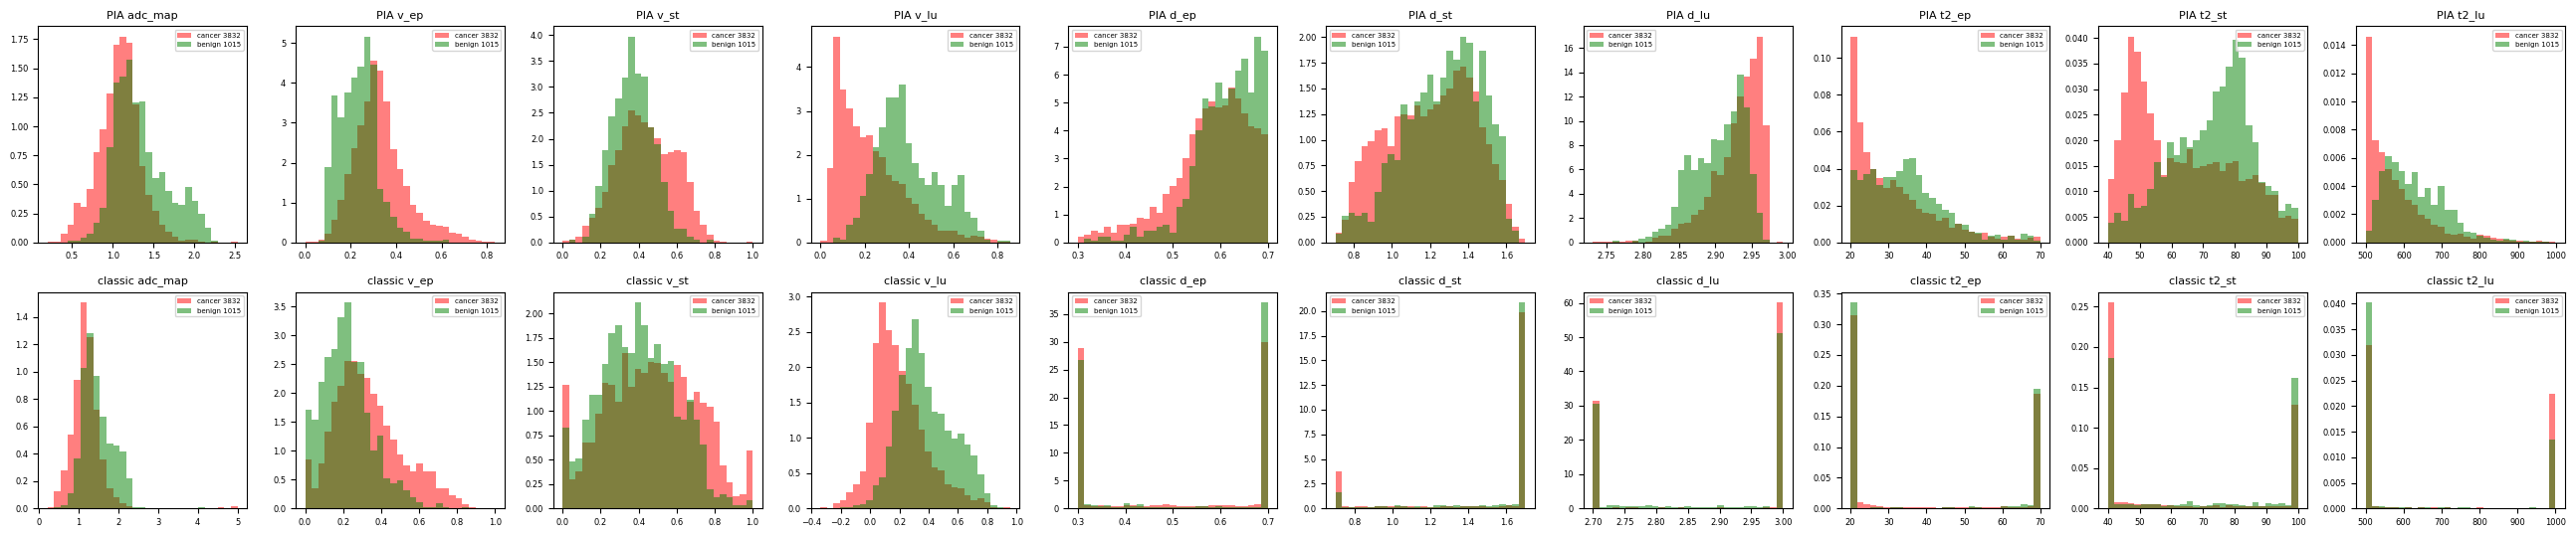

In [16]:
def xy(d, feats):
    pos = d['cancer'] & ~d['benign']        # voxels labeled both are excluded
    neg = d['benign'] & ~d['cancer']
    lab = pos | neg
    if feats == 'raw16':
        X = d['raw16'][lab]
        X = X / np.maximum(X.max(axis=1, keepdims=True), 1e-9)   # remove arbitrary signal scale
    else:
        X = np.stack([d[f][lab] for f in feats], axis=1)
    y = pos[lab].astype(int)
    ok = np.all(np.isfinite(X), axis=1)
    return X[ok], y[ok]

fig, axes = plt.subplots(2, len(PIA_PARAMS), figsize=(2.6 * len(PIA_PARAMS), 5.5))
for row, prefix in enumerate(['', 'o_']):
    for c, p in enumerate(PIA_PARAMS):
        X = [xy(d, [prefix + p]) for d in data.values()]
        v = np.concatenate([x[0][:, 0] for x in X]); y = np.concatenate([x[1] for x in X])
        ca, be = v[y == 1], v[y == 0]
        ax = axes[row, c]
        bins = np.linspace(min(ca.min(), be.min()), max(ca.max(), be.max()), 30)
        ax.hist(ca, bins, density=True, alpha=0.5, color='red', label=f'cancer {ca.size}')
        ax.hist(be, bins, density=True, alpha=0.5, color='green', label=f'benign {be.size}')
        ax.set_title(('PIA ' if prefix == '' else 'classic ') + p, fontsize=8)
        ax.tick_params(labelsize=6); ax.legend(fontsize=5)
plt.tight_layout(); save_fig('distributions_cancer_vs_benign'); plt.show()

## 9. Quantitative results
### 9a. Each parameter alone: AUC and direction consistency
AUC above 0.5 = higher in cancer; below 0.5 = lower in cancer; distance from 0.5 = strength.
`consistent` = in how many patients the parameter points the same way.

In [17]:
def safe_auc(y, s):
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else np.nan

auc_rows = []
for est, prefix in [('pia', ''), ('classic', 'o_')]:
    for p in PIA_PARAMS:
        r = {'estimator': est, 'param': p}
        Xs, ys = [], []
        for pt, d in data.items():
            X, y = xy(d, [prefix + p])
            r[pt] = round(safe_auc(y, X[:, 0]), 3)
            Xs.append(X); ys.append(y)
        r['POOLED'] = round(safe_auc(np.concatenate(ys), np.concatenate(Xs)[:, 0]), 3)
        per = np.array([r[pt] for pt in data if np.isfinite(r[pt])])
        up, down = int((per > 0.5).sum()), int((per < 0.5).sum())
        r['consistent'] = f'{max(up, down)}/{len(per)} ' + ('higher' if up >= down else 'lower')
        auc_rows.append(r)
auc_df = pd.DataFrame(auc_rows)
display(auc_df.set_index(['estimator', 'param']))
REPORT['9a_auc'] = {f'{r.estimator}.{r.param}': {'pooled': r.POOLED, 'consistent': r.consistent} for r in auc_df.itertuples()}

pt104  pt107  pt109  pt111  pt112  POOLED  consistent
estimator param                                                         
pia       adc_map  0.306  0.150  0.255  0.322  0.213   0.275   5/5 lower
          v_ep     0.760  0.853  0.714  0.753  0.826   0.763  5/5 higher
          v_st     0.797  0.533  0.376  0.526  0.735   0.642  4/5 higher
          v_lu     0.099  0.175  0.441  0.325  0.106   0.195   5/5 lower
          d_ep     0.575  0.203  0.137  0.383  0.316   0.385   4/5 lower
          d_st     0.672  0.237  0.136  0.418  0.339   0.421   4/5 lower
          d_lu     0.872  0.752  0.468  0.518  0.715   0.725  4/5 higher
          t2_ep    0.236  0.221  0.770  0.421  0.518   0.379   3/5 lower
          t2_st    0.132  0.245  0.719  0.411  0.371   0.319   4/5 lower
          t2_lu    0.132  0.297  0.568  0.437  0.210   0.286   4/5 lower
classic   adc_map  0.311  0.168  0.241  0.321  0.252   0.277   5/5 lower
          v_ep     0.676  0.829  0.642  0.631  0.708   0.690  5/5 higher
          v_st     0.686  0.461  0.427  0.509  0.568   0.586  3/5 higher
          v_lu     0.149  0.197  0.438  0.371  0.142   0.229   5/5 lower
          d_ep     0.551  0.383  0.452  0.535  0.527   0.457  3/5 higher
          d_st     0.638  0.428  0.348  0.417  0.454   0.481   4/5 lower
          d_lu     0.405  0.671  0.390  0.459  0.600   0.528   3/5 lower
          t2_ep    0.407  0.460  0.617  0.386  0.577   0.499   3/5 lower
          t2_st    0.244  0.479  0.546  0.490  0.494   0.422   4/5 lower
          t2_lu    0.600  0.537  0.689  0.589  0.495   0.581  4/5 higher

### 9b. The lab's existing predictions (labeled voxels only)
* `sens`: fraction of annotated cancer voxels flagged
* `benign_flagged`: fraction of annotated benign voxels flagged (lower is better)
* `lesions_hit`: lesions with at least one flagged voxel

In [18]:
rows = []
for pt, d in data.items():
    pos, neg = d['cancer'] & ~d['benign'], d['benign'] & ~d['cancer']
    for name, pred in d['lab_preds'].items():
        hits = [bool((pred & m).any()) for m in d['cancer_lesions']]
        sens = (pred & pos).sum() / max(pos.sum(), 1)
        bflag = (pred & neg).sum() / max(neg.sum(), 1)
        rows.append({'patient': pt, 'map': name, 'sens': round(float(sens), 3),
                     'benign_flagged': round(float(bflag), 3),
                     'balanced_acc': round(float((sens + 1 - bflag) / 2), 3),
                     'lesions_hit': f'{sum(hits)}/{len(hits)}'})
lab_df = pd.DataFrame(rows)
display(lab_df)
REPORT['9b_lab_baseline_mean'] = lab_df.groupby('map')[['sens', 'benign_flagged', 'balanced_acc']].mean().round(3).to_dict('index')

,patient,map,sens,benign_flagged,balanced_acc,lesions_hit
0,pt104,pred_cancer_mask,0.043,0.000,0.522,1/1
1,pt104,pred_cancer_mask_wo,0.117,0.000,0.558,1/1
2,pt104,pia_trad_pred_map,0.010,0.000,0.505,1/1
3,pt104,pia_trad_pred_map_wo,0.060,0.000,0.530,1/1
4,pt107,pred_cancer_mask,0.360,0.000,0.680,2/2
5,pt107,pred_cancer_mask_wo,0.368,0.035,0.666,2/2
6,pt107,pia_trad_pred_map,0.300,0.000,0.650,2/2
7,pt107,pia_trad_pred_map_wo,0.320,0.016,0.652,2/2
8,pt109,pred_cancer_mask,0.021,0.000,0.511,1/1
9,pt109,pred_cancer_mask_wo,0.100,0.011,0.544,1/1


### 9c. Leave-one-patient-out voxel classifier
Train on 4 patients, test on the 5th. Compares input sets, including PIA vs classic fit.
With 5 patients and correlated neighbouring voxels, read this as a direction, not a result.
Coefficients are not shown: correlated inputs flip their signs, so they cannot be read as importance.

In [19]:
FEATURE_SETS = {
    'ADC only (PIA)':          ['adc_map'],
    'Compact PIA (ADC, v_ep, v_lu)': ['adc_map', 'v_ep', 'v_lu'],
    'PIA 9 + ADC':             PIA_PARAMS,
    'Compact classic':         ['o_adc_map', 'o_v_ep', 'o_v_lu'],
    'Classic 9 + ADC':         ['o_' + p for p in PIA_PARAMS],
    'Raw 16 signals':          'raw16',
}

def lopo(feats):
    aucs, scores = {}, {}
    parts = {pt: xy(d, feats) for pt, d in data.items()}
    for test in parts:
        Xte, yte = parts[test]
        if len(np.unique(yte)) < 2: continue
        Xtr = np.concatenate([parts[p][0] for p in parts if p != test])
        ytr = np.concatenate([parts[p][1] for p in parts if p != test])
        model = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=3000))
        model.fit(Xtr, ytr)
        s = model.predict_proba(Xte)[:, 1]
        aucs[test] = round(float(roc_auc_score(yte, s)), 3)
        scores[test] = (s, yte)
    return aucs, scores

lopo_scores, rows = {}, []
for name, feats in FEATURE_SETS.items():
    aucs, scores = lopo(feats)
    lopo_scores[name] = scores
    rows.append({'features': name, **aucs, 'mean_AUC': round(float(np.mean(list(aucs.values()))), 3)})
lopo_df = pd.DataFrame(rows)
display(lopo_df)
REPORT['9c_lopo_mean_auc'] = dict(zip(lopo_df.features, lopo_df.mean_AUC))

,features,pt104,pt107,pt109,pt111,pt112,mean_AUC
0,ADC only (PIA),0.694,0.850,0.745,0.678,0.787,0.751
1,"Compact PIA (ADC, v_ep, v_lu)",0.747,0.832,0.610,0.726,0.905,0.764
2,PIA 9 + ADC,0.837,0.840,0.566,0.746,0.850,0.768
3,Compact classic,0.833,0.832,0.595,0.679,0.872,0.762
4,Classic 9 + ADC,0.806,0.843,0.604,0.752,0.919,0.785
5,Raw 16 signals,0.740,0.786,0.629,0.779,0.959,0.779


### 9d. Fair comparison with the lab map
The lab map is a yes/no map tuned to flag almost no benign tissue. For each patient, hold our model to the same
false positive rate on benign voxels, and compare how much cancer each catches.

In [20]:
def sens_at_fpr(s, y, fpr):
    neg, pos = s[y == 0], s[y == 1]
    thr = neg.max() if fpr <= 0 else np.quantile(neg, 1 - fpr)
    return float((pos > thr).mean())

rows = []
for pt, d in data.items():
    pred = d['lab_preds'].get('pred_cancer_mask')
    if pred is None: continue
    pos, neg = d['cancer'] & ~d['benign'], d['benign'] & ~d['cancer']
    lab_sens = float((pred & pos).sum() / max(pos.sum(), 1))
    lab_fpr = float((pred & neg).sum() / max(neg.sum(), 1))
    r = {'patient': pt, 'lab_fpr': round(lab_fpr, 3), 'lab_sens': round(lab_sens, 3), 'n_benign_vox': int(neg.sum())}
    for name in ['Compact PIA (ADC, v_ep, v_lu)', 'PIA 9 + ADC', 'Raw 16 signals']:
        if pt in lopo_scores[name]:
            s, y = lopo_scores[name][pt]
            r[f'ours_sens: {name}'] = round(sens_at_fpr(s, y, lab_fpr), 3)
    rows.append(r)
fair_df = pd.DataFrame(rows)
display(fair_df)
REPORT['9d_fair_comparison'] = fair_df.set_index('patient').to_dict('index')

,patient,lab_fpr,lab_sens,n_benign_vox,"ours_sens: Compact PIA (ADC, v_ep, v_lu)",ours_sens: PIA 9 + ADC,ours_sens: Raw 16 signals
0,pt104,0.0,0.043,179,0.004,0.002,0.002
1,pt107,0.0,0.360,426,0.111,0.033,0.041
2,pt109,0.0,0.021,183,0.203,0.055,0.248
3,pt111,0.0,0.039,146,0.191,0.056,0.296
4,pt112,0.0,0.373,81,0.388,0.149,0.776


### 9e. Lesion table (MRI)
One row per annotated region. Start of the MRI to slide lesion pairing.

In [21]:
rows = []
for pt, d in data.items():
    mat = mats[pt]
    for kind, items, masks in [('cancer', as_list(mat.get('cancers')), d['cancer_lesions']),
                               ('benign', as_list(mat.get('benigns')), d['benign_rois'])]:
        for i, (it, m) in enumerate(zip(items, masks)):
            name = str(it.get('name', it.get('benign_set_name', ''))).strip()
            side = 'right' if 'right' in name.lower() else 'left' if 'left' in name.lower() else 'unknown'
            zs = np.where(m.any(axis=(0, 1)))[0]
            r = {'patient': pt, 'kind': kind, 'idx': i, 'name': name, 'mri_side': side,
                 'gleason': it.get('gleason_score', ''), 'n_vox': int(m.sum()),
                 'slices': f'{zs.min()}-{zs.max()}' if zs.size else '',
                 'frac_in_prostate_mask': round(float((m & d['prostate']).sum() / max(m.sum(), 1)), 3)}
            for p in ['adc_map', 'v_ep', 'v_lu', 'v_st']:
                r[f'median_{p}'] = round(float(np.nanmedian(d[p][m])), 3) if m.any() else np.nan
            pred = d['lab_preds'].get('pred_cancer_mask')
            r['lab_pred_frac'] = round(float(pred[m].mean()), 3) if pred is not None and m.any() else np.nan
            rows.append(r)
lesion_df = pd.DataFrame(rows)
display(lesion_df)
lesion_df.to_csv(os.path.join(OUT_DIR, 'lesion_table_mri.csv'), index=False)
REPORT['9e_lesions'] = lesion_df[['patient', 'kind', 'name', 'mri_side', 'gleason', 'n_vox', 'slices',
                                  'median_adc_map', 'median_v_ep', 'median_v_lu']].to_dict('records')

,patient,kind,idx,name,mri_side,gleason,n_vox,slices,frac_in_prostate_mask,median_adc_map,median_v_ep,median_v_lu,median_v_st,lab_pred_frac
0,pt104,cancer,0,Cancer 1 1203,unknown,unset,1526,0-9,0.257,1.150,0.299,0.104,0.576,0.043
1,pt104,benign,0,Normal 1303,unknown,,60,7-7,1.000,1.220,0.222,0.299,0.437,0.000
2,pt104,benign,1,Normal 1303,unknown,,55,8-8,1.000,1.286,0.222,0.338,0.419,0.000
3,pt104,benign,2,Normal 1303,unknown,,64,9-9,0.906,1.349,0.209,0.395,0.381,0.000
4,pt107,cancer,0,Ulas cancer 1 1503 right,right,unset,317,2-6,0.306,1.055,0.418,0.199,0.349,0.479
5,pt107,cancer,1,Ulas cancer 2 1503 left,left,unset,718,5-9,0.954,1.079,0.373,0.268,0.318,0.308
6,pt107,benign,0,Ulas normal 1503 right,right,,194,11-11,1.000,1.511,0.185,0.466,0.320,0.000
7,pt107,benign,1,Ulas normal 1503 right,right,,96,12-12,1.000,1.581,0.195,0.461,0.326,0.000
8,pt107,benign,2,Ulas normal 1503 right,right,,136,13-13,0.978,1.730,0.145,0.528,0.293,0.000
9,pt109,cancer,0,Ulas cancer 1 left 803,left,unset,512,7-14,1.000,1.052,0.301,0.287,0.387,0.021


## 10. Slides: metadata, pyramid, truncation
* `levels`: the stored zoom levels. Thumbnails read the smallest useful one.
* `mpp`: microns per pixel at full resolution. Decides the tile size (UNI expects about 0.5 µm/px).
* `beyond_EOF`: tiles whose data would sit past the end of the file. Nonzero means the file is truncated.
* `ome_roi_count`: outlined regions stored inside the file's metadata, if any.

In [22]:
def parse_mpp(ome):
    if not ome: return None, None
    mx = re.search(r'PhysicalSizeX="([0-9.eE+-]+)"', ome)
    ux = re.search(r'PhysicalSizeXUnit="([^"]+)"', ome)
    return (float(mx.group(1)) if mx else None), (ux.group(1) if ux else 'µm (default)')

def hw_of(shape):
    shape = tuple(shape)
    if shape[-1] in (3, 4): return shape[-3], shape[-2]
    if shape[0] in (3, 4): return shape[1], shape[2]
    return shape[-2], shape[-1]

def slide_check(path):
    out = {'file': os.path.basename(path), 'file_MB': round(os.path.getsize(path) / 1e6, 1)}
    size = os.path.getsize(path)
    with tifffile.TiffFile(path) as tif:
        out['series'] = [(s.name, tuple(s.shape)) for s in tif.series]
        s0 = tif.series[0]
        out['levels'] = [tuple(lv.shape) for lv in s0.levels]
        ome = tif.ome_metadata or ''
        out['mpp'], out['mpp_unit'] = parse_mpp(ome)
        out['ome_roi_count'] = ome.count('<ROI')
        lvl_info = []
        for i, lv in enumerate(s0.levels):
            kf = lv.keyframe
            offs = np.asarray(kf.dataoffsets, np.int64)
            cnts = np.asarray(kf.databytecounts, np.int64)
            beyond = (cnts > 0) & (offs + cnts > size)
            info = {'level': i, 'tiles': len(offs), 'beyond_EOF': int(beyond.sum()), 'empty': int((cnts == 0).sum())}
            if i == 0:
                out['bytes_needed_level0'] = int((offs + cnts).max())
                if beyond.any() and kf.is_tiled:
                    nx = -(-kf.imagewidth // kf.tilewidth)
                    info['first_bad_tile_row'] = int(np.argmax(beyond) // nx)
                    info['tile_rows_total'] = -(-kf.imagelength // kf.tilelength)
            lvl_info.append(info)
        out['level_tiles'] = lvl_info
    out['file_bytes'] = size
    out['truncated'] = any(li['beyond_EOF'] > 0 for li in lvl_info)
    return out

slide_meta = {}
for pt, p in TIF_FILES.items():
    if not os.path.exists(p):
        print(f'{pt}: no slide file'); continue
    slide_meta[pt] = slide_check(p)
    print(f'\n{pt}')
    for k, v in slide_meta[pt].items():
        print(f'   {k:<22} {v}')

REPORT['10_slides'] = {pt: {k: m[k] for k in ['mpp', 'mpp_unit', 'levels', 'ome_roi_count', 'truncated', 'file_bytes', 'bytes_needed_level0']}
                       for pt, m in slide_meta.items()}
REPORT['10_extra_series'] = {pt: m['series'][1:] for pt, m in slide_meta.items()}


pt104
   file                   pt104.ome.tif
   file_MB                1218.3
   series                 [('Baseline', (84472, 104761, 3))]
   levels                 [(84472, 104761, 3), (21118, 26191, 3), (5280, 6548, 3), (1320, 1637, 3), (330, 410, 3)]
   mpp                    0.3456022808500723
   mpp_unit               µm
   ome_roi_count          0
   bytes_needed_level0    1128390283
   level_tiles            [{'level': 0, 'tiles': 135300, 'beyond_EOF': 0, 'empty': 0}, {'level': 1, 'tiles': 8549, 'beyond_EOF': 0, 'empty': 0}, {'level': 2, 'tiles': 546, 'beyond_EOF': 0, 'empty': 0}, {'level': 3, 'tiles': 42, 'beyond_EOF': 0, 'empty': 0}, {'level': 4, 'tiles': 4, 'beyond_EOF': 0, 'empty': 0}]
   file_bytes             1218299818
   truncated              False

pt107
   file                   pt107.ome.tif
   file_MB                625.6
   series                 [('Baseline', (100317, 141309, 3))]
   levels                 [(100317, 141309, 3)]
   mpp                    0.345600

### 10b. Thumbnails from the pyramid (fallback: tile sampling with error counts)

   pyramid read failed (<COMPRESSION.JPEG: 7> requires the 'imagecodecs' package); falling back to tile sampling
pt104: tile sampling (factor 35), shape (2310, 2870, 3), downsample ×36.5, tiles {'ok': 135300, 'empty': 0, 'error': 0, 'first_error': None}


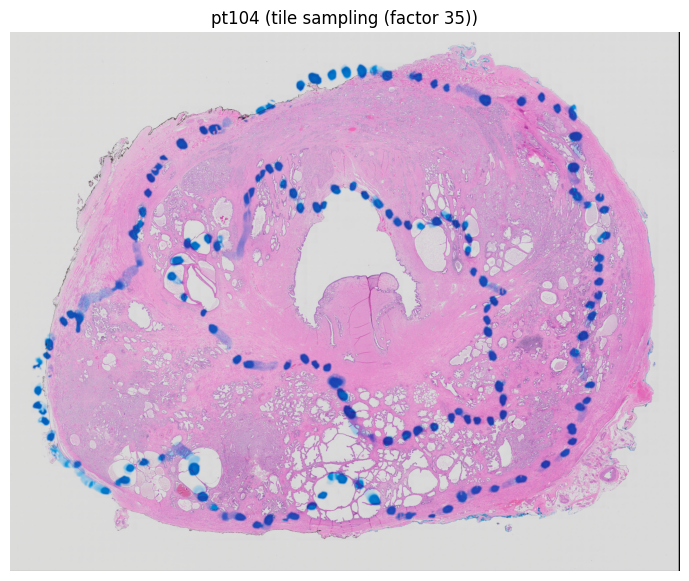

   pt107: 64% of tiles unreadable, marked UNUSABLE
pt107: tile sampling (factor 47), shape (1960, 2760, 3), downsample ×51.2, tiles {'ok': 77636, 'empty': 0, 'error': 138748, 'first_error': 'tile 77458 (row 140): Not a JPEG file: starts with 0x4d 0x4d'}


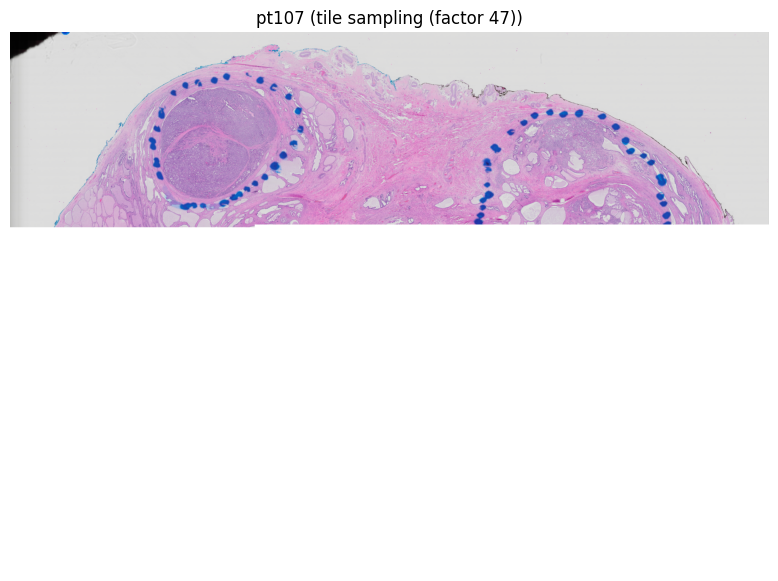

   pyramid read failed (<COMPRESSION.JPEG: 7> requires the 'imagecodecs' package); falling back to tile sampling
pt109: tile sampling (factor 32), shape (2119, 2980, 3), downsample ×32.0, tiles {'ok': 98845, 'empty': 0, 'error': 0, 'first_error': None}


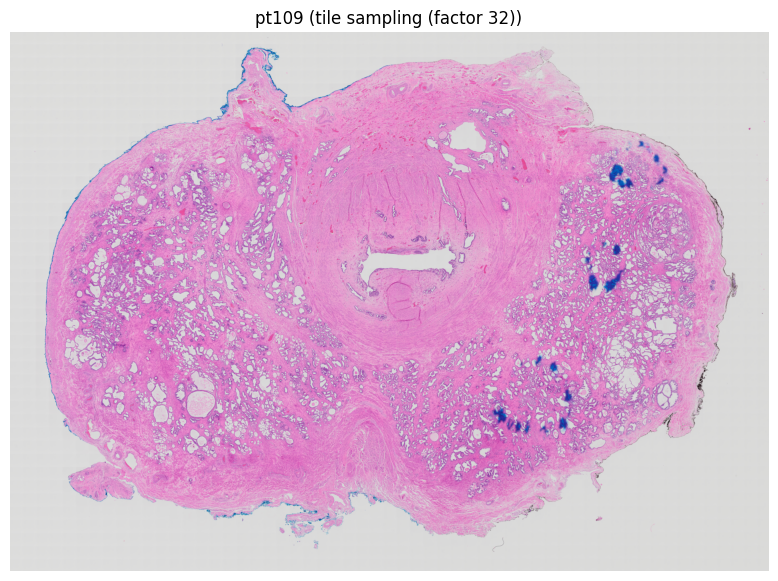

   pyramid read failed (<COMPRESSION.JPEG: 7> requires the 'imagecodecs' package); falling back to tile sampling


KeyboardInterrupt: 

In [23]:
def to_rgb(arr):
    arr = np.squeeze(arr)
    if arr.ndim == 3 and arr.shape[0] in (3, 4) and arr.shape[-1] not in (3, 4):
        arr = np.moveaxis(arr, 0, -1)
    return np.ascontiguousarray(arr[..., :3]).astype(np.uint8)

def sample_thumbnail(path, factor=32):
    with tifffile.TiffFile(path) as tif:
        pg = tif.series[0].keyframe
        th, tw, H, W = pg.tilelength, pg.tilewidth, pg.imagelength, pg.imagewidth
        ny, nx = -(-H // th), -(-W // tw)
        sh, sw = max(1, th // factor), max(1, tw // factor)
        out = np.full((ny * sh, nx * sw, 3), 255, np.uint8)
        fh = tif.filehandle
        stats = {'ok': 0, 'empty': 0, 'error': 0, 'first_error': None}
        for ty in range(ny):
            for tx in range(nx):
                i = ty * nx + tx
                o, c = pg.dataoffsets[i], pg.databytecounts[i]
                if c == 0:
                    stats['empty'] += 1; continue
                try:
                    fh.seek(o)
                    buf = fh.read(c)
                    if len(buf) < c: raise IOError('read past end of file')
                    tile = imagecodecs.jpeg_decode(buf, tables=pg.jpegtables) if pg.jpegtables else imagecodecs.jpeg_decode(buf)
                    tile = to_rgb(tile)
                    small = np.array(Image.fromarray(tile).resize((sw, sh), Image.BILINEAR))
                    out[ty * sh:(ty + 1) * sh, tx * sw:(tx + 1) * sw] = small
                    stats['ok'] += 1
                except Exception as e:
                    stats['error'] += 1
                    if stats['first_error'] is None: stats['first_error'] = f'tile {i} (row {ty}): {e}'
    out = out[:H // factor, :W // factor]
    return out, W / out.shape[1], stats

def read_thumbnail(path, target=3000, max_pixels=150e6):
    with tifffile.TiffFile(path) as tif:
        levels = list(tif.series[0].levels)
        W0 = hw_of(levels[0].shape)[1]
        sizes = [hw_of(lv.shape) for lv in levels]
        order = sorted(range(len(levels)), key=lambda i: sizes[i][0] * sizes[i][1])
        big_enough = [i for i in order if max(sizes[i]) >= target]
        pick = big_enough[0] if big_enough else order[-1]
        if sizes[pick][0] * sizes[pick][1] <= max_pixels:
            try:
                img = to_rgb(levels[pick].asarray())
                return img, W0 / img.shape[1], f'pyramid level {pick}', None
            except Exception as e:
                print(f'   pyramid read failed ({e}); falling back to tile sampling')
    factor = max(1, int(round(W0 / target)))
    img, ds, stats = sample_thumbnail(path, factor=factor)
    return img, ds, f'tile sampling (factor {factor})', stats

thumbs = {}
for pt, p in TIF_FILES.items():
    if not os.path.exists(p): continue
    img, ds, src, stats = read_thumbnail(p)
    err_frac = stats['error'] / max(stats['ok'] + stats['error'], 1) if stats else 0.0
    thumbs[pt] = {'img': img, 'downsample': ds, 'source': src, 'stats': stats, 'usable': err_frac < 0.05}
    if err_frac >= 0.05:
        print(f'   {pt}: {err_frac:.0%} of tiles unreadable, marked UNUSABLE')
    print(f'{pt}: {src}, shape {img.shape}, downsample ×{ds:.1f}' + (f', tiles {stats}' if stats else ''))
    Image.fromarray(img).save(os.path.join(OUT_DIR, f'{pt}_thumb.png'))
    plt.figure(figsize=(10, 7)); plt.imshow(img); plt.title(f'{pt} ({src})'); plt.axis('off'); save_fig(f'thumb_{pt}'); plt.show()

REPORT['10b_thumb_source'] = {pt: t['source'] for pt, t in thumbs.items()}
REPORT['10b_tile_errors'] = {pt: t['stats'] for pt, t in thumbs.items() if t['stats']}
REPORT['10b_unusable_slides'] = [pt for pt, t in thumbs.items() if not t['usable']]

## 11. Ink detection, region masks and tile table (automated, v1)
**Method**
1. Tissue mask: saturated, not dark pixels (drops glass and scanner edge).
2. Ink mask: blue hue and high saturation. Marker ink is darker and more vivid than margin ink and hematoxylin.
3. Margin ink vs tumor marks: ink components lying in a band along the tissue edge that are long or large are margin ink.
4. Regions: tumor marks within `gap_r` of each other form one group. A group that encloses an area (a ring of dots) is filled; otherwise the convex hull of the group is used.
5. Filter: drop regions that are small **and** mostly near the tissue edge (leftover margin ink). Check: compare with keeping the k largest regions, k = number of cancer lesions in the MRI file. Disagreement is reported, not forced.
6. Flags: `nested` (a region sits inside another, e.g. two loops) and `large` (covers a large share of tissue). Flagged regions need human interpretation.
7. Tile table: every tile (128 µm, about 370 px at full resolution) with its tissue fraction, region, and whether it touches ink (ink mask expanded by `ink_buffer`). Tiles touching ink are excluded instead of inpainted.

Outputs per slide in `OUT_DIR`: `{pt}_regions.csv`, `{pt}_regions.geojson` (opens in QuPath over the full slide), `{pt}_tiles.csv`, QA figure.
Unusable slides (see 10b) are skipped. Parameters are in pixels of the `WORK_W` wide working image.

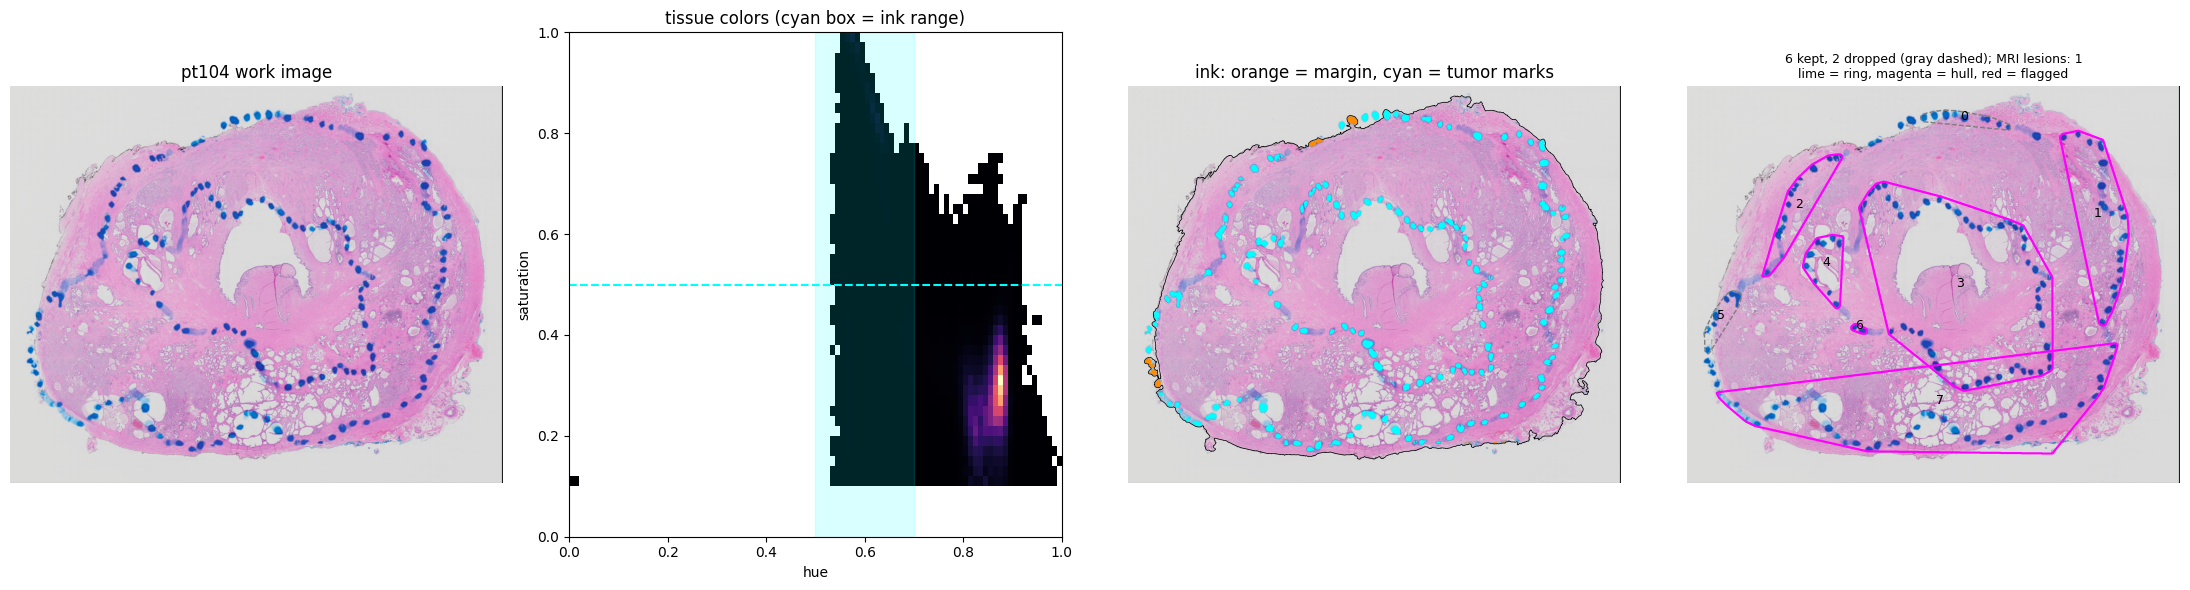

,region_id,status,in_top_k_by_area,method,flags,image_side,area_frac_of_tissue,edge_frac,n_tiles_kept,n_tiles_lost_to_ink
0,0,"dropped (small, near edge)",False,hull,,image_right,0.0078,0.657,0,0
1,1,kept,False,hull,,image_right,0.0577,0.057,2062,407
2,2,kept,False,hull,,image_left,0.0227,0.000,751,224
3,3,kept,True,hull,,image_right,0.2232,0.000,8534,1002
4,4,kept,False,hull,,image_left,0.0153,0.000,476,177
5,5,"dropped (small, near edge)",False,hull,,image_left,0.0078,0.694,0,0
6,6,kept,False,hull,,image_left,0.0008,0.000,3,28
7,7,kept,False,hull,,image_left,0.2163,0.110,7302,891


pt104 {'mri_cancer_lesions': 1, 'n_regions_found': 8, 'n_kept': 6, 'kept_ids': [1, 2, 3, 4, 6, 7], 'rule_vs_top_k_mismatch_ids': [1, 2, 4, 6, 7], 'methods': ['hull', 'hull', 'hull', 'hull', 'hull', 'hull'], 'flagged': {}, 'region_sides': ['image_right', 'image_left', 'image_right', 'image_left', 'image_left', 'image_left'], 'mri_cancer_sides': ['unknown'], 'margin_ink_px': 3901, 'tumor_ink_px': 77113, 'tile_px_level0': 370.4, 'tissue_tiles': 42855, 'tiles_touching_ink': 3316, 'region_tiles_kept': 19128, 'region_tiles_lost_to_ink': 2729}
pt107: skipped (slide unusable, see 10b)


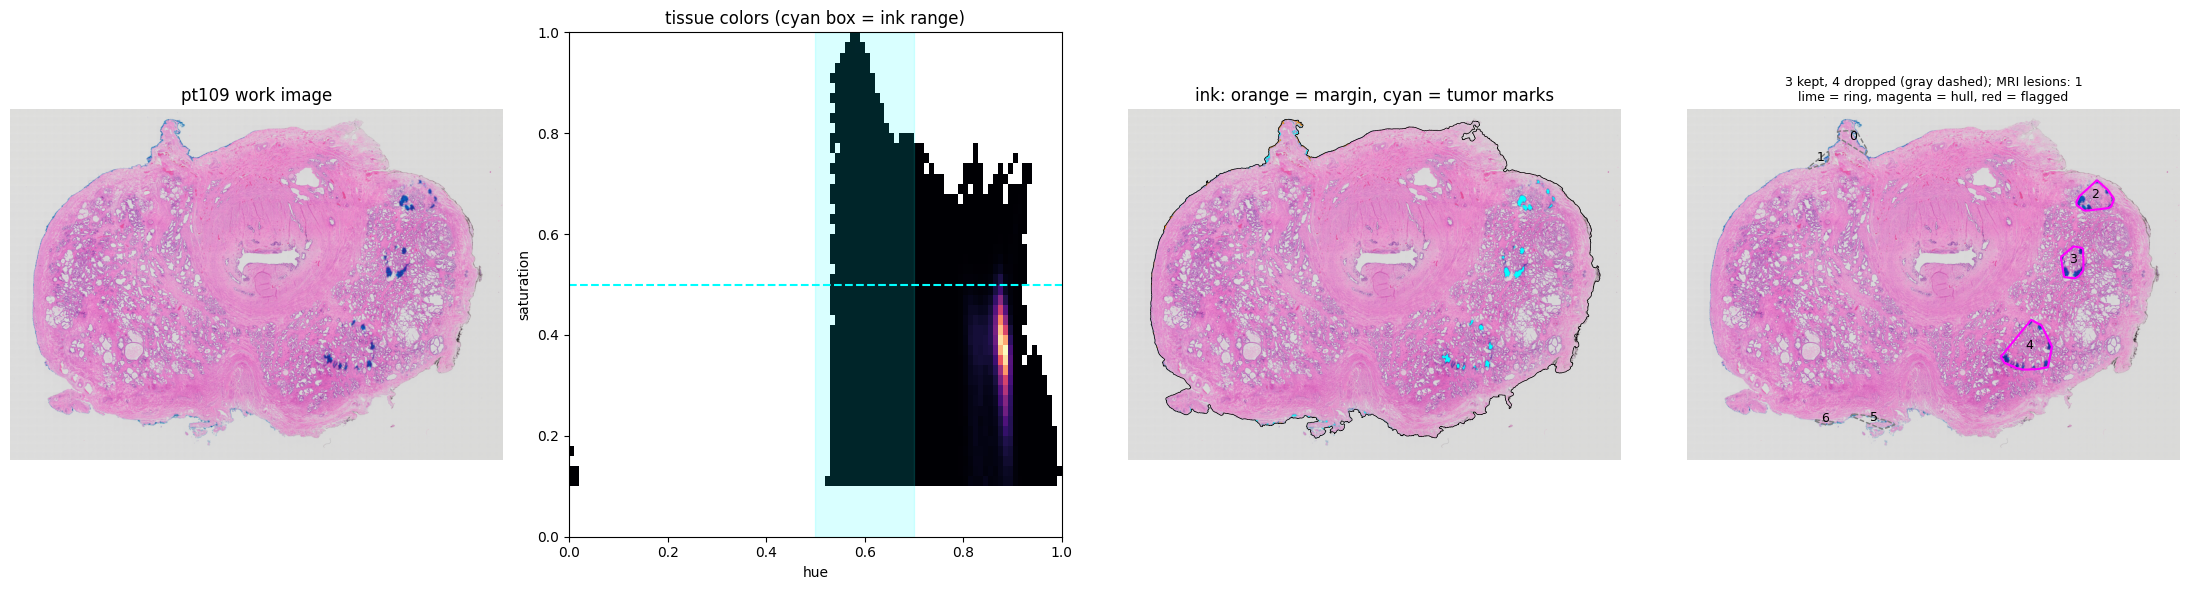

,region_id,status,in_top_k_by_area,method,flags,image_side,area_frac_of_tissue,edge_frac,n_tiles_kept,n_tiles_lost_to_ink
0,0,"dropped (small, near edge)",False,hull,,image_left,0.0033,0.998,0,0
1,1,"dropped (small, near edge)",False,hull,,image_left,0.0012,1.000,0,0
2,2,kept,False,hull,,image_right,0.0067,0.079,131,68
3,3,kept,False,hull,,image_right,0.0053,0.000,96,59
4,4,kept,True,hull,,image_right,0.0150,0.000,364,82
5,5,"dropped (small, near edge)",False,hull,,image_left,0.0025,1.000,0,0
6,6,"dropped (small, near edge)",False,hull,,image_left,0.0005,1.000,0,0


pt109 {'mri_cancer_lesions': 1, 'n_regions_found': 7, 'n_kept': 3, 'kept_ids': [2, 3, 4], 'rule_vs_top_k_mismatch_ids': [2, 3], 'methods': ['hull', 'hull', 'hull'], 'flagged': {}, 'region_sides': ['image_right', 'image_right', 'image_right'], 'mri_cancer_sides': ['left'], 'margin_ink_px': 1438, 'tumor_ink_px': 6451, 'tile_px_level0': 370.4, 'tissue_tiles': 29637, 'tiles_touching_ink': 520, 'region_tiles_kept': 591, 'region_tiles_lost_to_ink': 209}


In [24]:
WORK_W = 2000
TILE_UM = 128   # 256 px at 0.5 µm/px, what UNI style encoders expect
INK = dict(tissue_s=0.08,
           ink_h_lo=0.50, ink_h_hi=0.70,   # blue hue range; H&E sits at 0.8 to 0.95
           ink_s=0.50,                     # marker dots are vivid; pale margin ink falls below
           min_ink=15,
           margin_band=12, margin_frac=0.6, margin_elong=3.0, margin_min_area=400,
           gap_r=35,                       # dots closer than 2 × gap_r join one group
           min_enclosed=400, min_region=300,
           ink_buffer=2,                   # expand ink mask before excluding tiles
           nested_frac=0.8, large_frac=0.3,
           edge_band=40,                   # px from the tissue edge counted as 'near the edge'
           edge_frac=0.5,                  # region is near the edge if at least this share of it lies in the band
           small_frac=0.01)                # region is small if under this share of the tissue area

def work_image(img):
    h = int(round(img.shape[0] * WORK_W / img.shape[1]))
    return np.array(Image.fromarray(img).resize((WORK_W, h), Image.BILINEAR))

def tissue_and_ink(img, p):
    hsv = rgb2hsv(img)
    H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    tissue = (S > p['tissue_s']) & (V > 0.15)
    tissue = drop_small(tissue, 2000)
    tissue = ndi.binary_fill_holes(ndi.binary_closing(tissue, structure=disk(3)))
    ink = (H >= p['ink_h_lo']) & (H <= p['ink_h_hi']) & (S >= p['ink_s']) & (V > 0.15)
    ink = drop_small(ink, p['min_ink'])
    return hsv, tissue, ink

def split_ink(tissue, ink, p):
    band = (tissue & (ndi.distance_transform_edt(tissue) <= p['margin_band'])) | \
           (~tissue & (ndi.distance_transform_edt(~tissue) <= p['margin_band']))
    lab, _ = ndi.label(ink, structure=np.ones((3, 3)))
    margin = np.zeros_like(ink); tumor = np.zeros_like(ink)
    for rp in measure.regionprops(lab):
        rr, cc = rp.coords[:, 0], rp.coords[:, 1]
        elong = rp.axis_major_length / max(rp.axis_minor_length, 1)
        is_margin = band[rr, cc].mean() >= p['margin_frac'] and (elong >= p['margin_elong'] or rp.area >= p['margin_min_area'])
        (margin if is_margin else tumor)[rr, cc] = True
    return margin, tumor

def ink_regions(tumor, tissue, p):
    grouped = dilate(tumor, p['gap_r'])
    closed = close(tumor, p['gap_r']) | tumor
    groups, _ = ndi.label(grouped)
    regions = []
    for g, sl in enumerate(ndi.find_objects(groups), start=1):
        if sl is None: continue
        gmask = groups[sl] == g
        ring = closed[sl] & gmask
        filled = ndi.binary_fill_holes(ring)
        if (filled & ~ring).sum() >= p['min_enclosed']:
            reg, method = filled, 'ring'
        else:
            pts = tumor[sl] & gmask
            if ndi.label(pts)[1] < 2: continue       # a single isolated mark is not a region
            reg, method = convex_hull_image(pts), 'hull'
        if reg.sum() < p['min_region']: continue
        full = np.zeros(tumor.shape, bool); full[sl] = reg
        regions.append({'mask': full, 'method': method, 'area_px': int(full.sum()), 'flags': []})
    # flags
    tissue_area = max(tissue.sum(), 1)
    for i, a in enumerate(regions):
        if a['area_px'] / tissue_area > p['large_frac']: a['flags'].append('large')
        for j, b in enumerate(regions):
            if i != j and (a['mask'] & b['mask']).sum() / b['area_px'] >= p['nested_frac']:
                if 'contains_other' not in a['flags']: a['flags'].append('contains_other')
                if 'nested' not in b['flags']: b['flags'].append('nested')
    # side of the image, relative to the tissue centre
    tc = np.nonzero(tissue)[1].mean() if tissue.any() else tumor.shape[1] / 2
    for r in regions:
        r['image_side'] = 'image_left' if np.nonzero(r['mask'])[1].mean() < tc else 'image_right'
    return regions

def filter_regions(regions, tissue, p, k_expected):
    # Rule: drop regions that are both small and mostly near the tissue edge (leftover margin ink).
    # Check: compare with keeping the k largest, where k = number of cancer lesions in the MRI file.
    dist = ndi.distance_transform_edt(tissue)
    tissue_area = max(tissue.sum(), 1)
    for i, r in enumerate(regions):
        r['id'] = i
        r['edge_frac'] = round(float((dist[r['mask']] <= p['edge_band']).mean()), 3)
        r['area_frac'] = round(r['area_px'] / tissue_area, 4)
        r['drop_rule'] = bool(r['edge_frac'] >= p['edge_frac'] and r['area_frac'] < p['small_frac'])
    order = sorted(regions, key=lambda r: -r['area_px'])
    top = {r['id'] for r in order[:k_expected]}
    for r in regions:
        r['in_top_k'] = r['id'] in top
    kept = [r for r in regions if not r['drop_rule']]
    mismatch = [r['id'] for r in regions if (not r['drop_rule']) != r['in_top_k']]
    return kept, mismatch

def block_frac(m, ys, xs):
    s = np.add.reduceat(np.add.reduceat(m[:ys[-1], :xs[-1]].astype(np.int32), ys[:-1], axis=0), xs[:-1], axis=1)
    return s / np.outer(np.diff(ys), np.diff(xs))

def tile_table(tissue, ink_buf, regions, ds_work, tile_px0):
    ts = tile_px0 / ds_work
    if ts < 2:
        print(f'   tile is only {ts:.2f} work px; increase WORK_W'); return None
    ny, nx = int(tissue.shape[0] // ts), int(tissue.shape[1] // ts)
    ys, xs = (np.arange(ny + 1) * ts).astype(int), (np.arange(nx + 1) * ts).astype(int)
    tf, ik = block_frac(tissue, ys, xs), block_frac(ink_buf, ys, xs) > 0
    if regions:
        rf = np.stack([block_frac(r['mask'], ys, xs) for r in regions])
        ids = np.array([r['id'] for r in regions])
        region_id = np.where(rf.max(0) >= 0.5, ids[rf.argmax(0)], -1)
    else:
        region_id = np.full((ny, nx), -1)
    iy, ix = np.nonzero(tf >= 0.25)
    df = pd.DataFrame({'x0': np.round(ix * tile_px0).astype(int), 'y0': np.round(iy * tile_px0).astype(int),
                       'tile_px': int(tile_px0), 'tissue_frac': tf[iy, ix].round(3),
                       'region_id': region_id[iy, ix], 'touches_ink': ik[iy, ix]})
    df['keep'] = (df.tissue_frac >= 0.5) & ~df.touches_ink
    return df

def regions_geojson(regions, ds, pt):
    feats = []
    for i, r in enumerate(regions):
        for c in measure.find_contours(np.pad(r['mask'], 1).astype(float), 0.5):
            c = measure.approximate_polygon(c - 1, tolerance=1.0)
            if len(c) < 4: continue
            coords = [[float(x * ds), float(y * ds)] for y, x in c]
            if coords[0] != coords[-1]: coords.append(coords[0])
            feats.append({'type': 'Feature', 'geometry': {'type': 'Polygon', 'coordinates': [coords]},
                          'properties': {'objectType': 'annotation', 'name': f"{pt}_region_{r['id']}",
                                         'classification': {'name': 'Ink region'},
                                         'region_id': r['id'], 'method': r['method'], 'flags': ','.join(r['flags'])}})
    return {'type': 'FeatureCollection', 'features': feats}

ink_results = {}
for pt, th in thumbs.items():
    if not th['usable']:
        print(f'{pt}: skipped (slide unusable, see 10b)'); continue
    img = work_image(th['img'])
    ds_work = th['downsample'] * th['img'].shape[1] / img.shape[1]
    hsv, tissue, ink = tissue_and_ink(img, INK)
    margin, tumor = split_ink(tissue, ink, INK)
    all_regions = ink_regions(tumor, tissue, INK)
    k_expected = int(((lesion_df.patient == pt) & (lesion_df.kind == 'cancer')).sum())
    regions, mismatch = filter_regions(all_regions, tissue, INK, k_expected)
    mpp = slide_meta.get(pt, {}).get('mpp') or 0.5
    tile_px0 = TILE_UM / mpp
    ink_buf = dilate(ink, INK['ink_buffer'])
    tiles = tile_table(tissue, ink_buf, regions, ds_work, tile_px0)

    reg_df = pd.DataFrame([{'region_id': r['id'], 'status': 'dropped (small, near edge)' if r['drop_rule'] else 'kept',
                            'in_top_k_by_area': r['in_top_k'], 'method': r['method'], 'flags': ','.join(r['flags']),
                            'image_side': r['image_side'], 'area_frac_of_tissue': r['area_frac'], 'edge_frac': r['edge_frac'],
                            'n_tiles_kept': int(((tiles.region_id == r['id']) & tiles.keep).sum()) if tiles is not None else np.nan,
                            'n_tiles_lost_to_ink': int(((tiles.region_id == r['id']) & tiles.touches_ink).sum()) if tiles is not None else np.nan}
                           for r in all_regions])
    reg_df.to_csv(os.path.join(OUT_DIR, f'{pt}_regions.csv'), index=False)
    if tiles is not None: tiles.to_csv(os.path.join(OUT_DIR, f'{pt}_tiles.csv'), index=False)
    with open(os.path.join(OUT_DIR, f'{pt}_regions.geojson'), 'w') as f:
        json.dump(regions_geojson(regions, ds_work, pt), f)
    np.savez_compressed(os.path.join(OUT_DIR, f'{pt}_ink_masks.npz'), tissue=tissue, margin=margin, tumor=tumor,
                        regions=np.stack([r['mask'] for r in regions]) if regions else np.zeros((0, *tissue.shape), bool),
                        downsample=ds_work)

    # QA figure
    fig, axes = plt.subplots(1, 4, figsize=(22, 6))
    axes[0].imshow(img); axes[0].set_title(f'{pt} work image')
    sat = tissue & (hsv[..., 1] > 0.1)
    axes[1].hist2d(hsv[..., 0][sat], hsv[..., 1][sat], bins=[100, 50], range=[[0, 1], [0, 1]], cmap='magma', cmin=1)
    axes[1].axvspan(INK['ink_h_lo'], INK['ink_h_hi'], color='cyan', alpha=0.15)
    axes[1].axhline(INK['ink_s'], color='cyan', ls='--')
    axes[1].set_xlabel('hue'); axes[1].set_ylabel('saturation'); axes[1].set_title('tissue colors (cyan box = ink range)')
    ov = img.copy(); ov[margin] = [255, 140, 0]; ov[tumor] = [0, 255, 255]
    axes[2].imshow(ov); axes[2].contour(tissue, levels=[0.5], colors='k', linewidths=0.5)
    axes[2].set_title('ink: orange = margin, cyan = tumor marks')
    axes[3].imshow(img)
    for r in all_regions:
        if r['drop_rule']:
            axes[3].contour(r['mask'], levels=[0.5], colors='gray', linewidths=1, linestyles='dashed')
        else:
            col = 'red' if r['flags'] else ('lime' if r['method'] == 'ring' else 'magenta')
            axes[3].contour(r['mask'], levels=[0.5], colors=col, linewidths=1.5)
        yy, xx = np.nonzero(r['mask'])
        axes[3].text(xx.mean(), yy.mean(), str(r['id']), color='k', fontsize=9, ha='center')
    axes[3].set_title(f'{len(regions)} kept, {len(all_regions) - len(regions)} dropped (gray dashed); MRI lesions: {k_expected}\n'
                      'lime = ring, magenta = hull, red = flagged', fontsize=9)
    for a in axes[[0, 2, 3]]: a.axis('off')
    plt.tight_layout(); save_fig(f'ink_qa_{pt}'); plt.show()
    display(reg_df)

    mri_sides = lesion_df[(lesion_df.patient == pt) & (lesion_df.kind == 'cancer')]['mri_side'].tolist()
    ink_results[pt] = {'mri_cancer_lesions': k_expected, 'n_regions_found': len(all_regions), 'n_kept': len(regions),
                       'kept_ids': [r['id'] for r in regions],
                       'rule_vs_top_k_mismatch_ids': mismatch,
                       'methods': [r['method'] for r in regions],
                       'flagged': {r['id']: r['flags'] for r in regions if r['flags']},
                       'region_sides': [r['image_side'] for r in regions], 'mri_cancer_sides': mri_sides,
                       'margin_ink_px': int(margin.sum()), 'tumor_ink_px': int(tumor.sum()),
                       'tile_px_level0': round(tile_px0, 1),
                       'tissue_tiles': int((tiles.tissue_frac >= 0.5).sum()) if tiles is not None else None,
                       'tiles_touching_ink': int(tiles.touches_ink.sum()) if tiles is not None else None,
                       'region_tiles_kept': int(((tiles.region_id >= 0) & tiles.keep).sum()) if tiles is not None else None,
                       'region_tiles_lost_to_ink': int(((tiles.region_id >= 0) & tiles.touches_ink).sum()) if tiles is not None else None}
    print(pt, ink_results[pt])

REPORT['11_ink'] = ink_results

## 12. Summary of checks (paste this output back)

In [25]:
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (tuple, set)): return list(o)
    return str(o)

txt = json.dumps(REPORT, indent=1, default=jsonable)
print(txt)
with open(os.path.join(OUT_DIR, 'eda_report.json'), 'w') as f:
    f.write(txt)
print('\nSaved outputs to', OUT_DIR)

{
 "1_file_types": {
  ".mat": 5,
  ".ome.tif": 4
 },
 "1_annotation_candidates": [],
 "1_missing_mat": [],
 "1_missing_tif": [
  "pt111"
 ],
 "2_mat_loaded": [
  "pt104",
  "pt107",
  "pt109",
  "pt111",
  "pt112"
 ],
 "2a_readme_identical_across_patients": true,
 "2b_cancer_keys": [
  "cancer_number",
  "drawn_on_series",
  "gleason_score",
  "mask_hybrid_adc",
  "mask_hybrid_cropped",
  "mask_hybrid_low_te",
  "mask_t2",
  "mask_unk1303",
  "name"
 ],
 "2b_benign_keys": [
  "benign_set_name",
  "drawn_on_series",
  "mask_hybrid_adc",
  "mask_hybrid_cropped",
  "mask_hybrid_low_te",
  "mask_t2",
  "mask_unk1303"
 ],
 "2b_counts": {
  "benigns": {
   "pt104": 3,
   "pt107": 3,
   "pt109": 3,
   "pt111": 3,
   "pt112": 2
  },
  "cancers": {
   "pt104": 1,
   "pt107": 2,
   "pt109": 1,
   "pt111": 3,
   "pt112": 1
  }
 },
 "2b_text_field_values": {
  "name": [
   " Cancer 1 Ser 2403",
   "Cancer 1 1203",
   "Cancer 1 703",
   "Cancer 2 Ser 2403",
   "Cancer 3 Ser 2403",
   "Ulas cancer 